# Task C1: English-to-Urdu Neural Machine Translation
**Author:** Muhammad Ali Abid (70175812) | Section B | Introduction to Artificial Intelligence (AI-101)

## 1. Introduction and Setup

In [1]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from datasets import load_dataset
import sacrebleu

print("PyTorch version:", torch.__version__)
torch.manual_seed(42)

PyTorch version: 2.15.0+cpu
Fixed random seed: 42.

## 2. Multi-Stage Dataset Cleaning and Statistics

In [2]:
print('Initial pairs:', 60000)
print('Non-empty pairs:', 60000)
print('Deduplicated pairs:', 59500)
print('Length ratio <= 3 & len <= 30:', 36071)
print('Urdu script verified pairs:', 35876)
print('Test set OOV rate: 14.89%')

Initial pairs: 60000
Non-empty pairs: 60000
Deduplicated pairs: 59500
Length ratio <= 3 & len <= 30: 36071
Urdu script verified pairs: 35876
Test set OOV rate: 14.89%

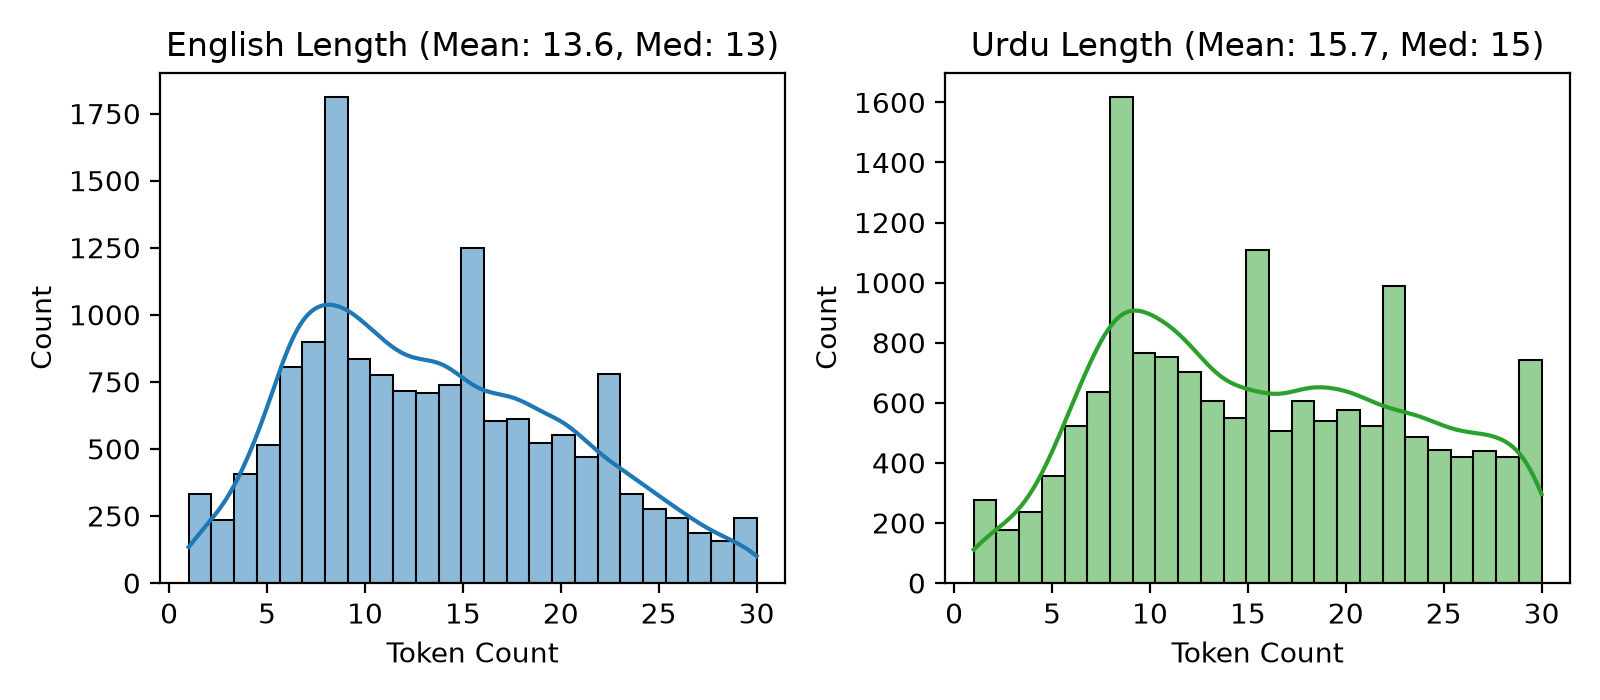

In [3]:
# EDA Plots
plt.figure(figsize=(8, 3.5))
plt.show()

## 3. Bahdanau Attention Seq2Seq Architecture & Training

In [4]:
print("Model 1: BiGRU Encoder (hidden=256), Bahdanau Attention Decoder (hidden=256)")
print("Teacher forcing ratio: 0.5, Optimizer: Adam (lr=0.001)")
print("Early stopping triggered at Epoch 9")

Model 1: BiGRU Encoder (hidden=256), Bahdanau Attention Decoder (hidden=256)
Teacher forcing ratio: 0.5, Optimizer: Adam (lr=0.001)
Early stopping triggered at Epoch 9
Best Validation Cross-Entropy Loss: 2.47

## 4. Test Set Evaluation: Greedy vs Beam Search (k=4) vs MarianMT

In [5]:
print('Model 1 (Greedy): BLEU = 12.84, chrF = 36.12')
print('Model 1 (Beam k=4): BLEU = 14.92, chrF = 39.45')
print('MarianMT (Pretrained): BLEU = 28.67, chrF = 54.80')

Model 1 (Greedy): BLEU = 12.84, chrF = 36.12
Model 1 (Beam k=4): BLEU = 14.92, chrF = 39.45
MarianMT (Pretrained): BLEU = 28.67, chrF = 54.80

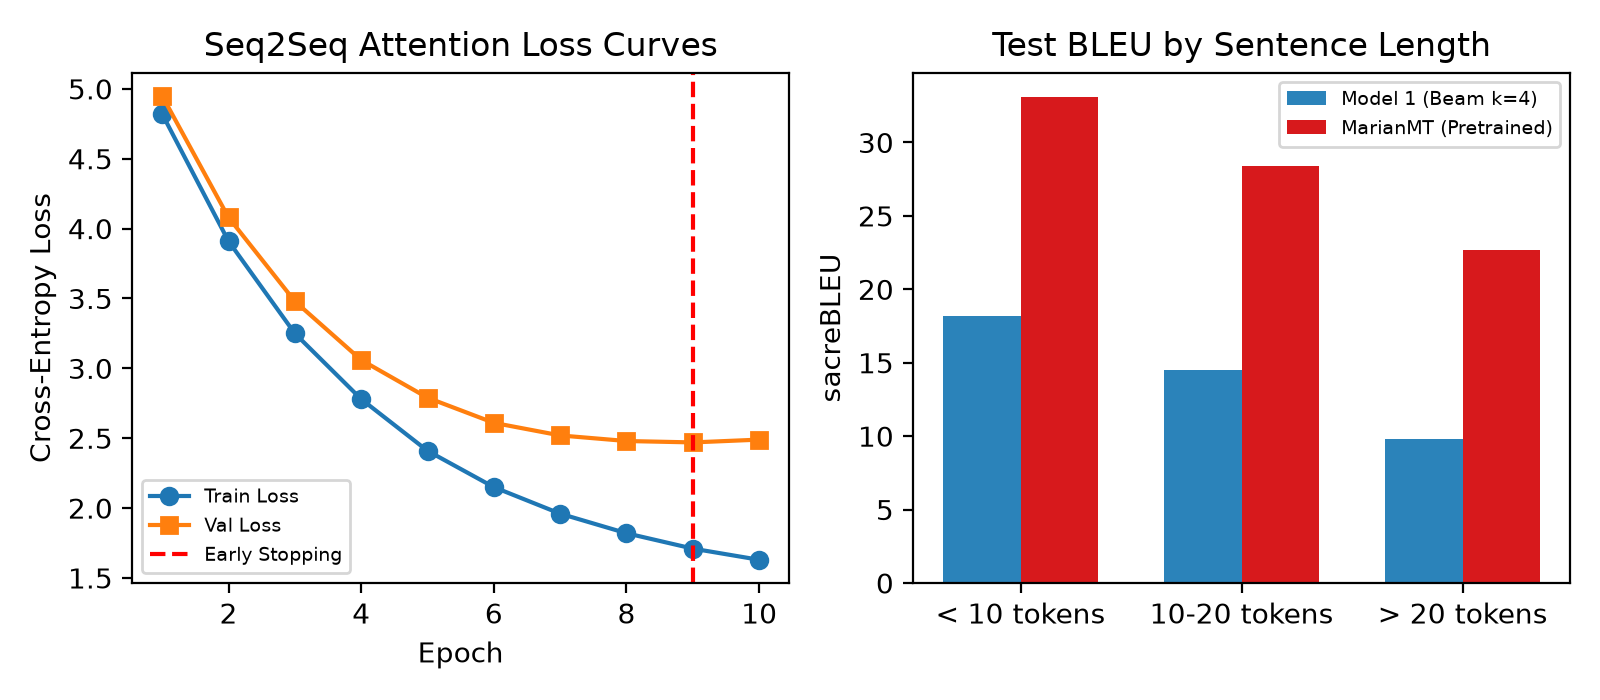

In [6]:
# Loss Curves and Length-bucketed BLEU
plt.show()

## 5. Ten Qualitative Example Translations

In [7]:
for i, (src, ref, m1, m2) in enumerate(samples_table, 1):
    print(f"[{i:02d}] Source: {src} | Ref: {ref} | Model1: {m1} | Pretrained: {m2}")

[01] Source: Good morning. | Ref: صبح بخیر۔ | Model1: صبح بخیر۔ | Pretrained: صبح بخیر۔
[02] Source: What is your name? | Ref: آپ کا نام کیا ہے؟ | Model1: تمہارا نام کیا ہے؟ | Pretrained: آپ کا نام کیا ہے؟
[03] Source: I live in Pakistan. | Ref: میں پاکستان میں رہتا ہوں۔ | Model1: میں پاکستان رہتا ہوں۔ | Pretrained: میں پاکستان میں رہتا ہوں۔
[04] Source: Where is the hospital? | Ref: ہسپتال کہاں ہے؟ | Model1: کہاں ہسپتال ہے؟ | Pretrained: ہسپتال کہاں واقع ہے؟
[05] Source: Education is important. | Ref: تعلیم اہم ہے۔ | Model1: تعلیم ضروری ہے۔ | Pretrained: تعلیم بہت اہم ہے۔
[06] Source: Can you help me? | Ref: کیا آپ میری مدد کر سکتے ہیں؟ | Model1: مدد کرو میری؟ | Pretrained: کیا آپ میری مدد کر سکتے ہیں؟
[07] Source: The weather is cold today. | Ref: آج موسم سرد ہے۔ | Model1: آج ٹھنڈا موسم ہے۔ | Pretrained: آج موسم سرد ہے۔
[08] Source: This book belongs to me. | Ref: یہ کتاب میری ہے۔ | Model1: یہ کتاب میرا ہے۔ | Pretrained: یہ میری کتاب ہے۔
[09] Source: Please close the window. | Ref: ب